### Lab 3 - Isolation Forest, LODA


In [1]:
pip install pyod

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.io import loadmat
from pyod.utils.utility import standardizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import warnings

warnings.filterwarnings("ignore", message=".*pin_memory.*")


#### Exercise 1.

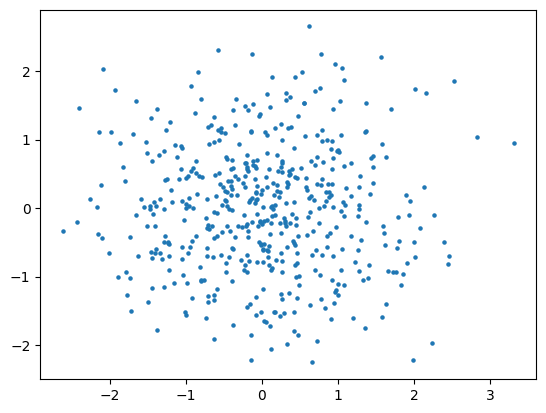

In [ ]:
X, y = make_blobs(n_samples=500, n_features=2, centers=[[0.0, 0.0]], cluster_std=1.0)
# cluster centered in (0, 0) and with standard deviation of sigma = 1
fig = plt.figure()
ax = fig.add_subplot()
ax.scatter(X[:, 0], X[:, 1], s=5)
plt.show()

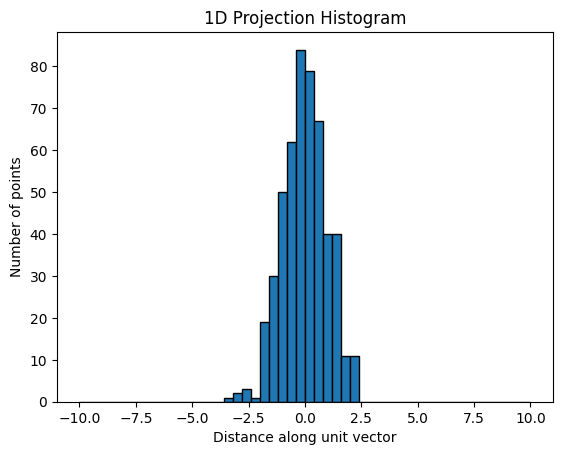

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  2  3  1 19 30 50 62
 84 79 67 40 40 11 11  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0]
[-10.   -9.6  -9.2  -8.8  -8.4  -8.   -7.6  -7.2  -6.8  -6.4  -6.   -5.6
  -5.2  -4.8  -4.4  -4.   -3.6  -3.2  -2.8  -2.4  -2.   -1.6  -1.2  -0.8
  -0.4   0.    0.4   0.8   1.2   1.6   2.    2.4   2.8   3.2   3.6   4.
   4.4   4.8   5.2   5.6   6.    6.4   6.8   7.2   7.6   8.    8.4   8.8
   9.2   9.6  10. ]
[0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.002 0.004 0.006 0.002 0.038 0.06  0.1   0.124
 0.168 0.158 0.134 0.08  0.08  0.022 0.022 0.    0.    0.    0.    0.
 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
 0.    0.   ]


In [ ]:
vectors = np.random.multivariate_normal(mean=(0,0), cov = np.eye(2), size=5) # 5 random vectors
projection_vectors = vectors / np.linalg.norm(vectors, axis=1).reshape(-1,1) # normalize them to obtain unit vectors


# here I checked how a histogram would look like (for a unit vector)
scalar_projections = X @ projection_vectors[0]
counts, bin_edges = np.histogram(scalar_projections, bins=50, range=(-10,10))
plt.hist(scalar_projections, bins=50, edgecolor='black', range=(-10,10))
plt.xlabel('Distance along unit vector')
plt.ylabel('Number of points')
plt.title('1D Projection Histogram')
plt.show()
print(counts)
print(bin_edges)

prob_per_bin = counts / X.shape[0]
print(prob_per_bin)

In [ ]:
def compute_hists(X, projection_vectors, nbins=50):
    probabilities_per_hist = []
    bin_edges_per_hist = []

    for proj_vect in projection_vectors:
        scalar_projections = X @ proj_vect
        counts, bin_edges = np.histogram(scalar_projections, bins=nbins, range=(-10,10))
        prob_per_bin = counts / X.shape[0]
        # print(prob_per_bin)
        probabilities_per_hist.append(prob_per_bin)
        bin_edges_per_hist.append(bin_edges)

    probabilities_per_hist = np.array(probabilities_per_hist)
    bin_edges_per_hist = np.array(bin_edges_per_hist)

    return probabilities_per_hist, bin_edges_per_hist


def compute_anomaly_scores(X_test, bin_edges_per_hist, probabilities_per_hist):

    X_test_proj = X_test @ projection_vectors.T
    anomaly_scores = np.zeros(X_test.shape[0])

    # for each unit vector (i):
    for i in range(len(projection_vectors)):
        # find the bin in which each point resides
        min_val = bin_edges_per_hist[i][0]
        bin_width = bin_edges_per_hist[i][1] - bin_edges_per_hist[i][0]
        bin_indices = np.floor((X_test_proj[:, i] - min_val) / bin_width).astype(int)

        probs = np.zeros(X_test.shape[0])
        # for each point, get the corresponding probability of the bin it resides in
        probs = probabilities_per_hist[i][bin_indices]
        anomaly_scores += probs

    anomaly_scores /= len(projection_vectors)
    # print(anomaly_scores.shape)
    return anomaly_scores

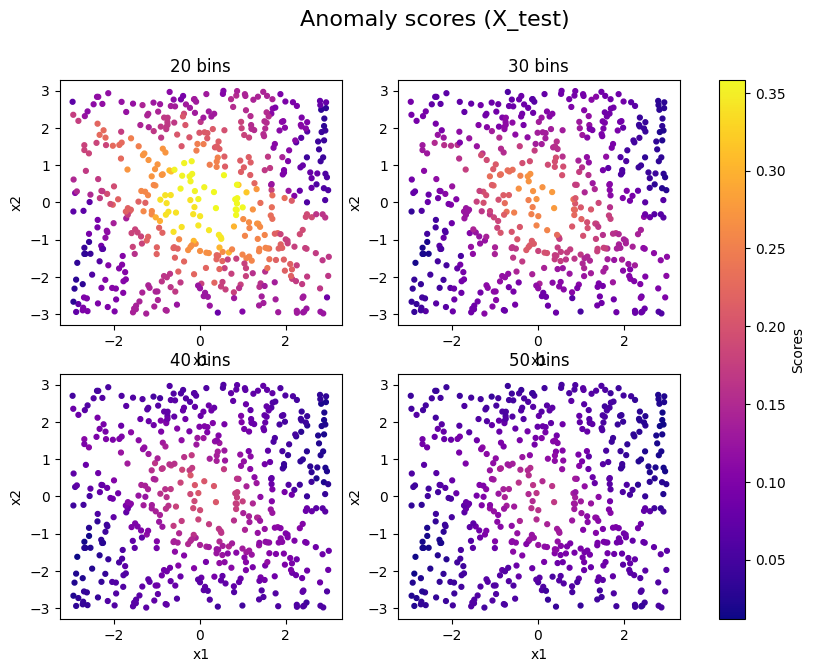

In [ ]:
X_test = np.random.uniform(-3.0, 3.0, size=(500,2))

all_anomaly_scores = []
no_bins = [20, 30, 40, 50]
for i, n in enumerate(no_bins):
    probabilities_per_hist, bin_edges_per_hist = compute_hists(X, projection_vectors, nbins=n)
    anomaly_scores = compute_anomaly_scores(X_test, bin_edges_per_hist, probabilities_per_hist)
    all_anomaly_scores.append(anomaly_scores)

vmin = min(s.min() for s in all_anomaly_scores)
vmax = max(s.max() for s in all_anomaly_scores)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()
for ax, n, scores in zip(axes.flatten(), no_bins, all_anomaly_scores):
    sc = ax.scatter(X_test[:, 0], X_test[:, 1], c=scores, cmap='plasma', s=12, vmin=vmin,vmax=vmax)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f'{n} bins')

fig.colorbar(sc, ax=axes, label='Scores')
plt.suptitle("Anomaly scores (X_test)", size=16)
plt.show()

The points with the lowest scores are the most likely to be anomalies. \
When less bins are used to create a histogram, the probability corresponding to each bin is higher, therefore the final anomaly scores are bigger.


#### Exercise 2.

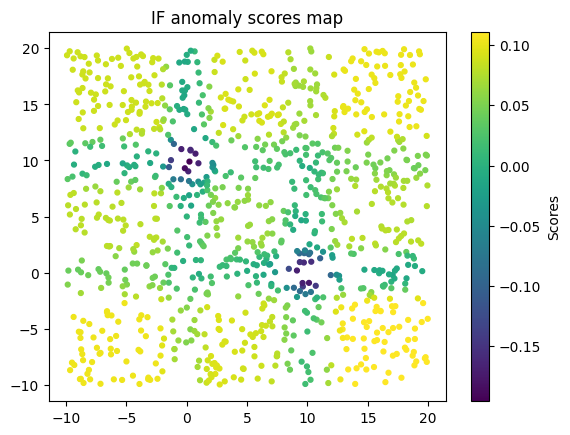

In [5]:
from pyod.models import iforest, dif, loda

X_train, y_train = make_blobs(n_samples=(500, 500), n_features=2, centers=((10.0, 0.0), (0.0, 10.0)), cluster_std=(1.0, 1.0))
X_test = np.random.uniform(-10.0, 20.0, size=(1000,2))

iforest_model = iforest.IForest(n_estimators=100, max_samples=256, contamination=0.02)
iforest_model.fit(X_train)
if_scores = iforest_model.decision_function(X_test)

plt.scatter(X_test[:, 0], X_test[:, 1], c=if_scores, cmap='viridis', s=12)
plt.colorbar(label='Scores')
plt.title("IF anomaly scores map")
plt.show()

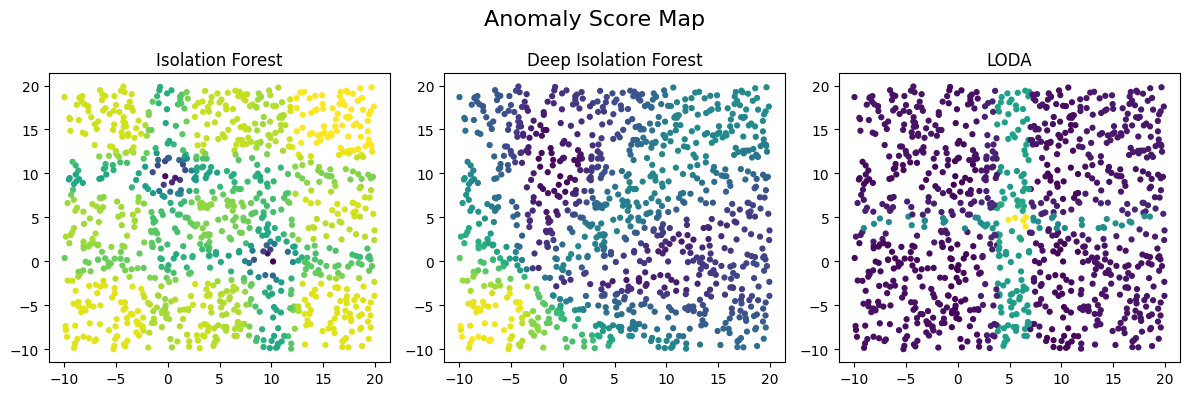

In [ ]:
dif_model = dif.DIF(batch_size=256, contamination=0.02, device='cpu')
dif_model.fit(X_train)
dif_scores = dif_model.decision_function(X_test)

loda_model = loda.LODA(contamination=0.02)
loda_model.fit(X_train)
loda_scores = loda_model.decision_function(X_test)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes = axes.flatten()

axes[0].scatter(X_test[:, 0], X_test[:, 1], c=if_scores, s=12)
axes[0].set_title("Isolation Forest")

axes[1].scatter(X_test[:, 0], X_test[:, 1], c=dif_scores, s=12)
axes[1].set_title("Deep Isolation Forest")

axes[2].scatter(X_test[:, 0], X_test[:, 1], c=loda_scores, s=12)
axes[2].set_title("LODA")

fig.suptitle(f'Anomaly Score Map', fontsize=16)
plt.tight_layout()
plt.show()


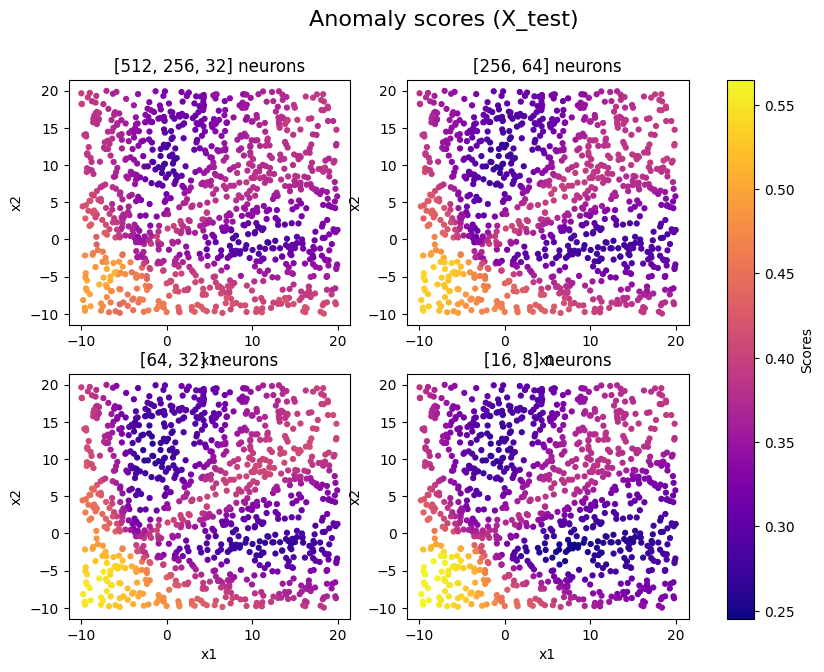

In [ ]:
hidden_layers = [[512, 256, 32], [256, 64], [64, 32], [16, 8]]

all_dif_scores = []
for h in hidden_layers:
    dif_model = dif.DIF(batch_size=256, hidden_neurons=h, contamination=0.02, device='cpu')
    dif_model.fit(X_train)
    dif_scores = dif_model.decision_function(X_test)
    all_dif_scores.append(dif_scores)

vmin = min(s.min() for s in all_dif_scores)
vmax = max(s.max() for s in all_dif_scores)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()
for ax, h, scores in zip(axes.flatten(), hidden_layers, all_dif_scores):
    sc = ax.scatter(X_test[:, 0], X_test[:, 1], c=scores, cmap='plasma', s=12, vmin=vmin,vmax=vmax)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f'{h} neurons')

fig.colorbar(sc, ax=axes, label='Scores')
plt.suptitle("Anomaly scores (X_test)", size=16)
plt.show()

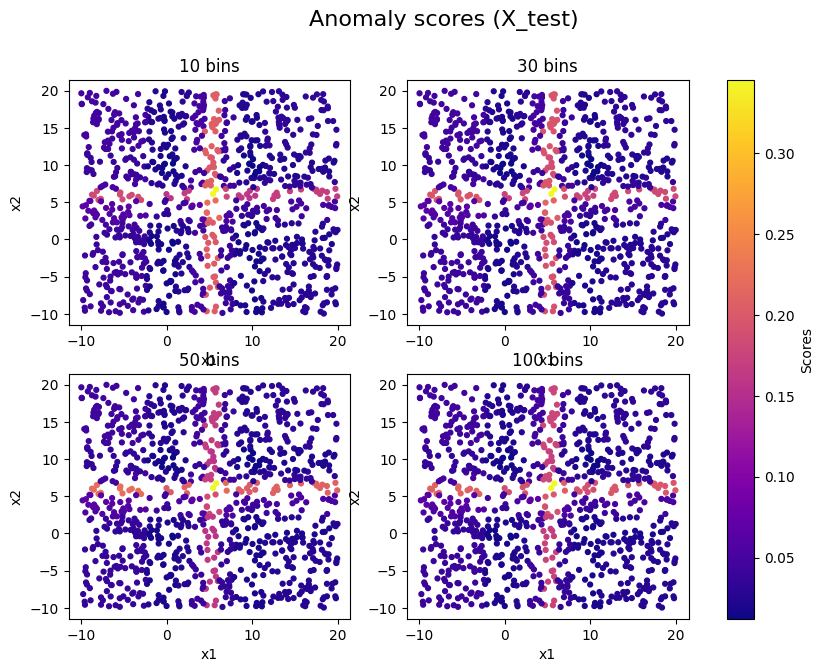

In [ ]:
nbins = [10, 30, 50, 100]

all_loda_scores = []
for i, n in enumerate(nbins):
    loda_model = loda.LODA(contamination=0.02)
    loda_model.fit(X_train)
    loda_scores = loda_model.decision_function(X_test)
    all_loda_scores.append(loda_scores)

vmin = min(s.min() for s in all_loda_scores)
vmax = max(s.max() for s in all_loda_scores)

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes = axes.flatten()
for ax, n, scores in zip(axes.flatten(), nbins, all_loda_scores):
    sc = ax.scatter(X_test[:, 0], X_test[:, 1], c=scores, cmap='plasma', s=12, vmin=vmin,vmax=vmax)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f'{n} bins')

fig.colorbar(sc, ax=axes, label='Scores')
plt.suptitle("Anomaly scores (X_test)", size=16)
plt.show()

The LODA algorithm uses random sparse projection vectors with $\sqrt{d}$ nonzero features, where d is the dimension of the dataset (https://anlearn.readthedocs.io/en/latest/loda.html). In our 2D case, it is highly likely that the vectors used are parallel with either of the feature axis, which is why the vertical and horizontal stripes appear in the feature map.

For the 3D data:

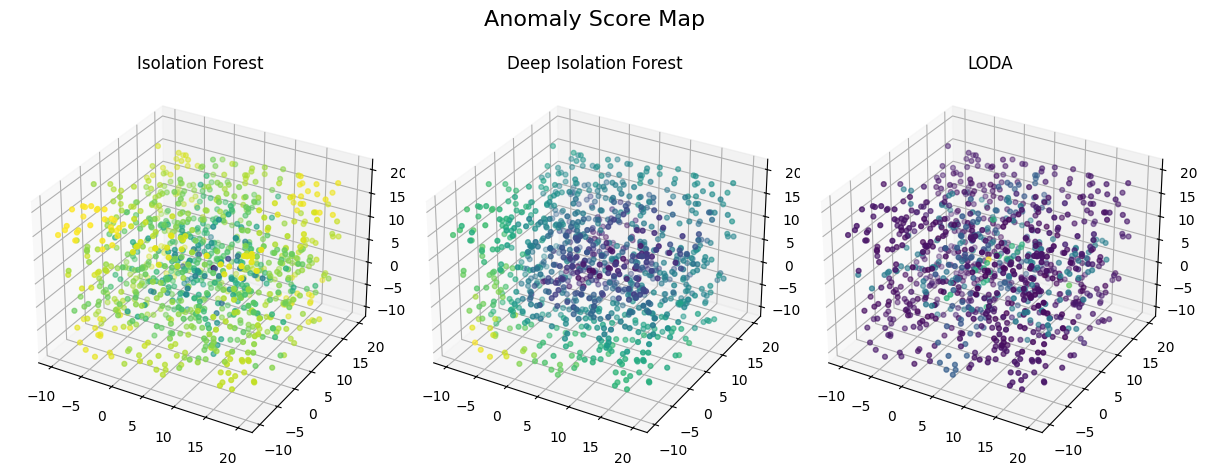

In [ ]:
X_train_3D, y_train = make_blobs(n_samples=(500, 500), n_features=2, centers=((0.0, 10.0, 0.0), (10.0, 0.0, 10.0)), cluster_std=(1.0, 1.0))
X_test_3D = np.random.uniform(-10.0, 20.0, size=(1000,3))

iforest_model = iforest.IForest(n_estimators=100, max_samples=256, contamination=0.02)
iforest_model.fit(X_train_3D)
if_scores = iforest_model.decision_function(X_test_3D)

dif_model = dif.DIF(batch_size=256, contamination=0.02)
dif_model.fit(X_train_3D)
dif_scores = dif_model.decision_function(X_test_3D)

loda_model = loda.LODA(contamination=0.02)
loda_model.fit(X_train_3D)
loda_scores = loda_model.decision_function(X_test_3D)

fig, axes = plt.subplots(1, 3,figsize=(12, 5),subplot_kw={'projection': '3d'})
axes = axes.flatten()

axes[0].scatter(X_test_3D[:, 0], X_test_3D[:, 1], X_test_3D[:, 2], c=if_scores, s=12)
axes[0].set_title("Isolation Forest")

axes[1].scatter(X_test_3D[:, 0], X_test_3D[:, 1], X_test_3D[:, 2], c=dif_scores, s=12)
axes[1].set_title("Deep Isolation Forest")

axes[2].scatter(X_test_3D[:, 0], X_test_3D[:, 1], X_test_3D[:, 2], c=loda_scores, s=12)
axes[2].set_title("LODA")

fig.suptitle(f'Anomaly Score Map', fontsize=16)
plt.tight_layout()
plt.show()

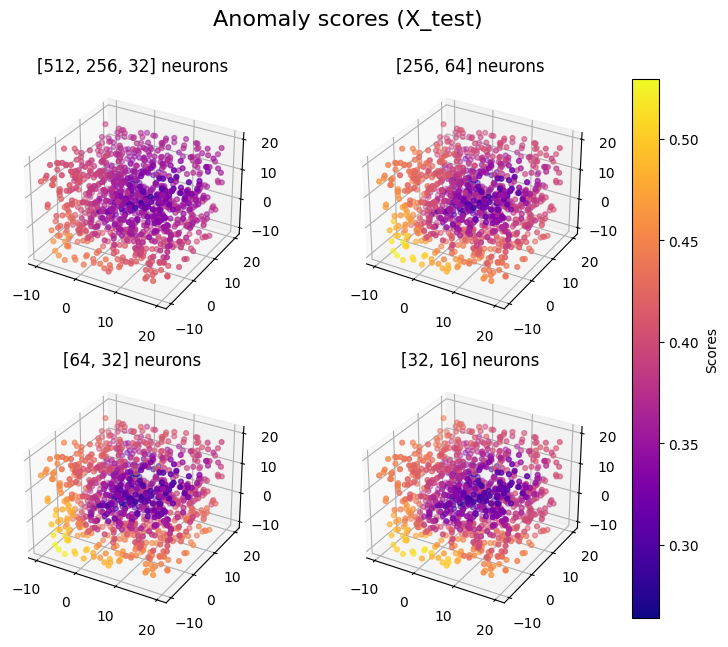

In [ ]:
hidden_layers = [[512, 256, 32], [256, 64], [64, 32], [32, 16]]

all_dif_scores = []
for h in hidden_layers:
    dif_model = dif.DIF(batch_size=256, hidden_neurons=h, contamination=0.02, device='cpu')
    dif_model.fit(X_train_3D)
    dif_scores = dif_model.decision_function(X_test_3D)
    all_dif_scores.append(dif_scores)

vmin = min(s.min() for s in all_dif_scores)
vmax = max(s.max() for s in all_dif_scores)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), subplot_kw={'projection': '3d'})
axes = axes.flatten()
for ax, h, scores in zip(axes.flatten(), hidden_layers, all_dif_scores):
    sc = ax.scatter(X_test_3D[:, 0], X_test_3D[:, 1], X_test_3D[:, 2], c=scores, cmap='plasma', s=12, vmin=vmin, vmax=vmax)
    ax.set_title(f'{h} neurons')

fig.colorbar(sc, ax=axes, label='Scores')
plt.suptitle("Anomaly scores (X_test)", size=16)
plt.show()

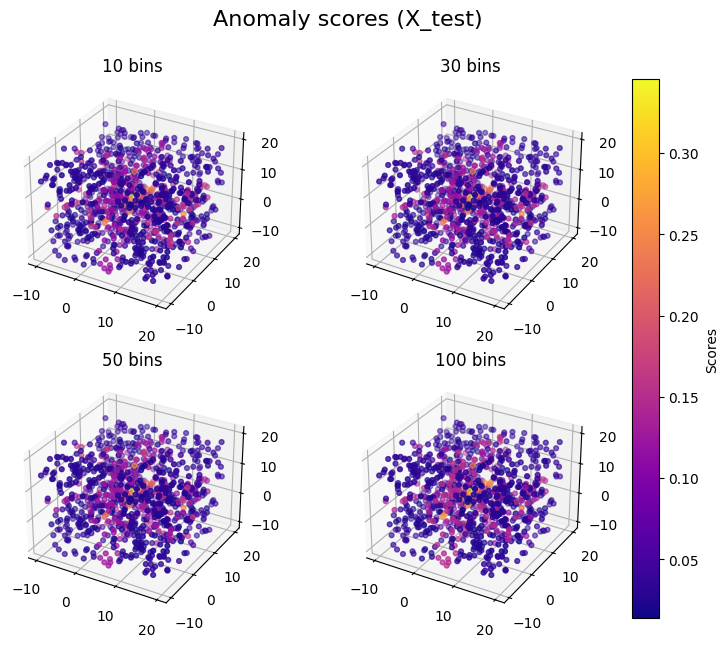

In [ ]:
nbins = [10, 30, 50, 100]

all_loda_scores = []
for i, n in enumerate(nbins):
    loda_model = loda.LODA(contamination=0.02)
    loda_model.fit(X_train_3D)
    loda_scores = loda_model.decision_function(X_test_3D)
    all_loda_scores.append(loda_scores)

vmin = min(s.min() for s in all_loda_scores)
vmax = max(s.max() for s in all_loda_scores)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), subplot_kw={'projection': '3d'})
axes = axes.flatten()
for ax, n, scores in zip(axes.flatten(), nbins, all_loda_scores):
    sc = ax.scatter(X_test_3D[:, 0], X_test_3D[:, 1], X_test_3D[:, 2], c=scores, cmap='plasma', s=12, vmin=vmin,vmax=vmax)
    ax.set_title(f'{n} bins')

fig.colorbar(sc, ax=axes, label='Scores')
plt.suptitle("Anomaly scores (X_test)", size=16)
plt.show()

#### Exercise 3.

In [7]:
dicti = loadmat('shuttle.mat')
X = dicti['X']
y = dicti['y'].ravel()

print(X.shape)
print(y.shape)

def compute_BA(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    TPR = TP / (TP + FN)
    TNR = TN / (TN + FP)
    BA = (TPR + TNR) / 2
    return BA

def get_stats_random_split(X, y):

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4)
    scaler = StandardScaler()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)
    cr = np.count_nonzero(y_train) / y_train.shape[0]

    iforest_model = iforest.IForest(n_estimators=100, max_samples=256, contamination=cr)
    _, m1_BA, _, m1_ROC = fit_predict_compute_metrics(iforest_model, X_train_norm, X_test_norm, y_train, y_test, cr)

    dif_model = dif.DIF(batch_size=1024, contamination=cr)
    _, m2_BA, _, m2_ROC = fit_predict_compute_metrics(dif_model, X_train_norm, X_test_norm, y_train, y_test, cr)

    loda_model = loda.LODA(contamination=cr)
    _, m3_BA, _, m3_ROC = fit_predict_compute_metrics(loda_model, X_train_norm, X_test_norm, y_train, y_test, cr)

    return [m1_BA, m1_ROC, m2_BA, m2_ROC, m3_BA, m3_ROC]

def fit_predict_compute_metrics(model, X_train, X_test, y_true_train, y_true_test, cr):
    model.fit(X_train)
    scores_train = model.decision_function(X_train)
    scores_test = model.decision_function(X_test)

    thresh = np.quantile(scores_train, 1 - cr)
    y_pred_train = (scores_train > thresh).astype(int)
    y_pred_test = (scores_test > thresh).astype(int)

    BA_train = compute_BA(y_true_train, y_pred_train)
    roc_auc_train = roc_auc_score(y_true_train, scores_train)
    BA_test = compute_BA(y_true_test, y_pred_test)
    roc_auc_test = roc_auc_score(y_true_test, scores_test)

    return BA_train, BA_test, roc_auc_train, roc_auc_test


(49097, 9)
(49097,)


In [8]:
all_stats = []
for i in range(10):
    stats_per_split = get_stats_random_split(X, y)
    all_stats.append(stats_per_split)
    print(f'Split {i+1} done.')

all_stats = np.array(all_stats)
mean_stats = np.mean(all_stats, axis=0) # on the columns => each of the 6 stats
names = ['IF_BA', 'IF_ROC', 'DIF_BA', 'DIF_ROC', 'LODA_BA', 'LODA_ROC']

for i, n in enumerate(names):
    print(f'{n} - {mean_stats[i]}')


Split 1 done.
Split 2 done.
Split 3 done.
Split 4 done.
Split 5 done.
Split 6 done.
Split 7 done.
Split 8 done.
Split 9 done.
Split 10 done.
IF_BA - 0.9688149606578819
IF_ROC - 0.9967393193444604
DIF_BA - 0.799842307569043
DIF_ROC - 0.9677133162624794
LODA_BA - 0.9738774016011951
LODA_ROC - 0.9903119328729103
